In [1]:
import numpy as np
import pandas as pd
import airfrans as af
import matplotlib.pyplot as plt
import matplotlib.tri as tri
from scipy.interpolate import griddata
from sklearn.neighbors import NearestNeighbors

In [2]:
PATH_TO_SAVING_DIRECTORY = "./data"
PATH_TO_DATASET = "./data/Dataset"
TASK = "full"

In [3]:
# Only run this cell once as we don't need to download the dataset multiple times
# af.dataset.download(root = PATH_TO_SAVING_DIRECTORY, unzip = True)

In [3]:
train_dataset, train_dataname = af.dataset.load(root = PATH_TO_DATASET, task = TASK, train = True)

test_dataset, test_dataname = af.dataset.load(root = PATH_TO_DATASET, task = TASK, train = False)

Loading dataset (task: full, split: test): 100%|██████████| 200/200 [00:36<00:00,  5.43it/s]


In [4]:
sim = train_dataset[0]
print("surface fraction:",  sim[:, 11].mean())   # expect ~0.5–2% (small portion on airfoil)
print("normals on surface:", sim[sim[:, 11] == 1, 5:7].mean(axis=0))  # nonzero
print("normals off surface:", sim[sim[:, 11] == 0, 5:7].mean(axis=0))  # ~0
print("inlet velocity unique values:", np.unique(sim[:, 2:4], axis=0).shape)  # should be exactly 1 row

surface fraction: 0.005638249887235002
normals on surface: [0.31267021 0.02428704]
normals off surface: [0. 0.]
inlet velocity unique values: (1, 2)


In [5]:
cols = [
    # inputs
    "x", "y",
    "u_xin", "u_yin", # inlet velocity x, y component
    "distance", # distance to airfoil
    "nx", "ny", # normal x, y component normal direction sticks straight out of the surface
    
    # targets
    "vx", "vy", # velocity
    "pressure",# kinematic pressure (p/ρ) (m²/s²)
    "nu_t", # turbulent viscosity (m²/s)
    
    # mask
    "surface" # surface indicator (point lies on airfoil or not)
    
]

In [6]:
df = pd.DataFrame(train_dataset[100], columns = cols)

x = df["x"]
y = df["y"]
vx = df["vx"]
vy = df["vy"]
surface = df["surface"]

### Display mesh

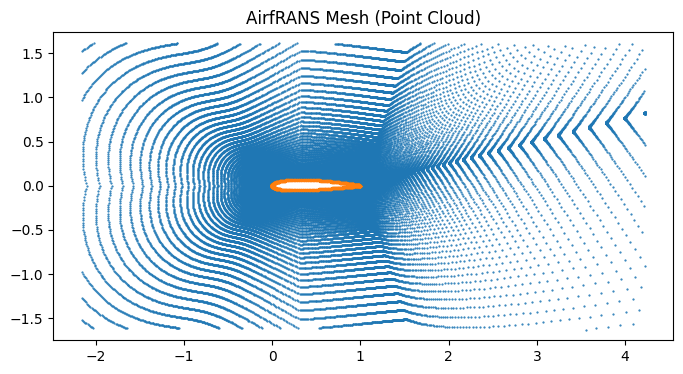

In [7]:
# point cloud
plt.figure(figsize=(8, 4))
plt.scatter(x[surface == 0], y[surface == 0], s=0.3, label="Flow field")
plt.scatter(x[surface == 1], y[surface == 1], s=2, label="Airfoil surface")
plt.axis("equal")
plt.title("AirfRANS Mesh (Point Cloud)")
plt.show()

### Visualise pressure, velocity, streamline

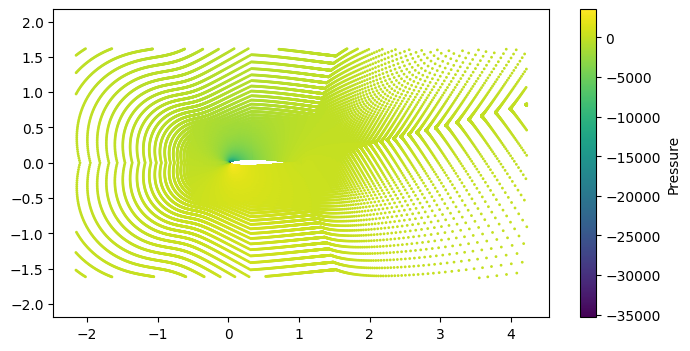

In [8]:
# pressure

plt.figure(figsize=(8,4))
plt.scatter(
    x,
    y,
    c=df["pressure"],
    s=1
)

plt.colorbar(label="Pressure")
plt.axis("equal")
plt.show()

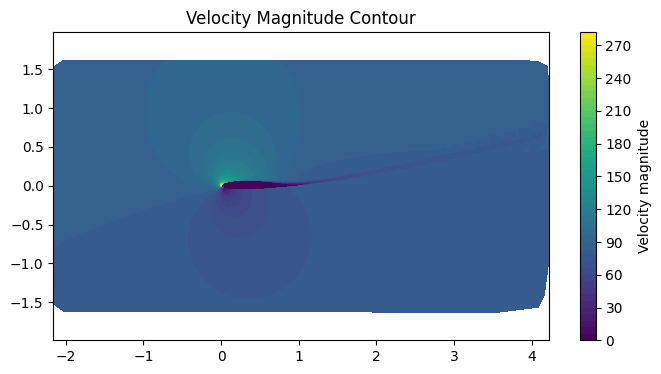

In [9]:
# velocity

df["velocity"] = np.sqrt(df["vx"]**2 + df["vy"]**2)

plt.figure(figsize=(8,4))
plt.tricontourf(
    x,
    y,
    df["velocity"],
    levels=50, 
    cmap="viridis"

)

plt.colorbar(label="Velocity magnitude")
plt.axis("equal")
plt.title("Velocity Magnitude Contour")
plt.show()

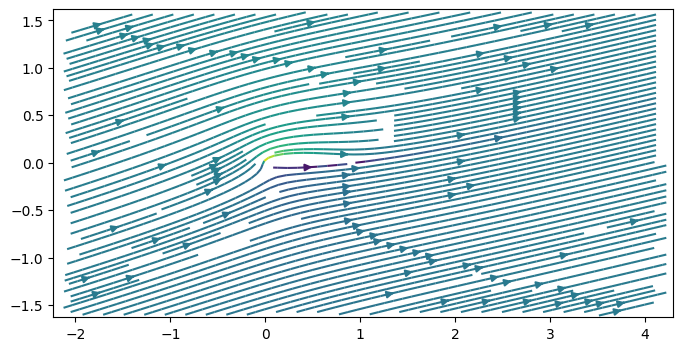

In [10]:
# Streamline

# 1 - interpolation
xi = np.linspace(df["x"].min(), df["x"].max(), 200)
yi = np.linspace(df["y"].min(), df["y"].max(), 200)

X, Y = np.meshgrid(xi, yi)

# interpolate velocity onto grid
VX = griddata((x, y), vx, (X, Y), method="linear")
VY = griddata((x, y), vy, (X, Y), method="linear")

plt.figure(figsize = (8,4))

V = np.sqrt(VX**2 + VY**2)

plt.streamplot(
    X, Y,
    VX, VY,
    color=V,
    cmap="viridis",
    density=2
)

# plt.scatter(x, y, s=0.1, color="black", alpha=0.2)

plt.axis("equal")
plt.show()

In [12]:
# Mesh-based streamline tracing


In [11]:
class Normaliser:

    def _init(self):
        self.feature_mean = None
        self.feature_std = None
        self.target_mean = None
        self.target_std = None


    def fit(self, feature_list, target_list):
        feature = np.concatenate(feature_list, axis=0)
        target = np.concatenate(target_list, axis=0)

        self.feature_mean, self.feature_std = feature.mean(axis=0), feature.std(axis=0) + 1e-8
        self.target_mean, self.target_std = target.mean(axis=0), target.std(axis=0) + 1e-8

    def transform_feature(self, feature):
        return (feature - self.feature_mean)/self.feature_std
    
    def transform_target(self, target):
        return (target - self.target_mean)/self.target_std
    
    def inverse_target(self, target):
        return target * self.target_std + self.target_mean
    
    def save(self, path):
        np.savez(path, 
                 x_mean = self.feature_mean,
                 x_std = self.feature_std,
                 y_mean = self.target_mean,
                 y_std = self.target_std)
        
    def load(self, path):
        d = np.load(path)
        self.feature_mean, self.feature_std = d["x_mean"], d["x_std"]
        self.target_mean, d.target_std = d["y_mean"], d["y_std"]

In [12]:
sim = train_dataset[1]
print(sim.shape)

n = Normaliser()
n.fit([sim[:, 0:7]], [sim[:, 7:11]])

print(n.feature_mean)
print(n.feature_std)

print((n.transform_feature(sim[:, 0:7])).mean(axis=0))
print((n.transform_feature(sim[:, 0:7])).std(axis=0))

(170180, 12)
[ 4.87830133e-01  1.48868764e-03  5.87172837e+01 -3.65611185e+00
  2.37907786e-01  1.74464976e-03  1.04686929e-04]
[7.24262257e-01 3.31376367e-01 1.00256222e-08 1.00056031e-08
 4.83627161e-01 4.10968480e-02 6.20891628e-02]
[ 3.44237507e-15  3.39567238e-16  2.55566893e-03 -5.59993588e-04
 -5.26874870e-15 -5.11433834e-14  2.58681255e-14]
[9.99999986e-01 9.99999970e-01 4.66163566e-15 1.44339835e-15
 9.99999979e-01 9.99999757e-01 9.99999839e-01]


In [13]:
rng = np.random.RandomState(42)
n_sims = len(train_dataset)
idx = rng.permutation(n_sims) # randomly shuffles a sequence or returns a permuted range, returning a new copy instead of modifying the original array in place
idx.shape

(800,)

In [14]:
train_idx = idx[:int(0.9*n_sims)].tolist()
val_idx = idx[int(0.9*n_sims):].tolist()
print(len(train_idx), len(val_idx))

720 80


In [15]:
feature_list = []
target_list = []

for i in train_idx:
    sim = train_dataset[i]
    feature_list.append(sim[:, 0:7])
    target_list.append(sim[:, 7:11])

norm = Normaliser()
norm.fit(feature_list, target_list)
norm.save("normaliser.npz")


In [16]:
print(sim[:,0].max())
print(sim[:,0].min())
print(sim[:,1].max())
print(sim[:,1].min())

4.226963520050049
-2.159684419631958
1.6201319694519043
-1.6187922954559326


In [17]:
# grid extent and resolution
X_MIN, X_MAX = -2.0, 4.0
Y_MIN, Y_MAX = -1.5, 1.5
GRID_RES_X = 128
GRID_RES_Y = 64

In [18]:
# interpolate one channel to the grid
from scipy.interpolate import griddata

sim = train_dataset[0]
pos = sim[:, 0:2]
distance = sim[:, 4]

# IMPORTANT: 2d array (rows, columns) = (height, width) = (y, x)
gx, gy = np.meshgrid(
    np.linspace(X_MIN, X_MAX, GRID_RES_X),
    np.linspace(Y_MIN, Y_MAX, GRID_RES_Y)
)

print(gx.shape)
distance_grid = griddata(pos, distance, (gx, gy))

print(distance_grid.shape)
print(np.isnan(distance_grid).any())

(64, 128)
(64, 128)
False


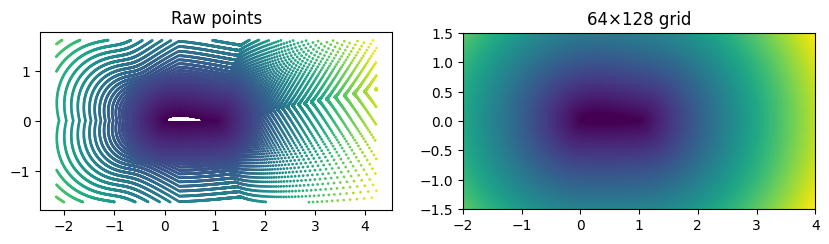

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10,4))
ax[0].scatter(pos[:, 0], pos[:, 1], c=distance, s=1, cmap = "viridis")
ax[0].set_title('Raw points')
ax[0].set_aspect("equal")
ax[1].imshow(distance_grid, extent = [X_MIN, X_MAX, Y_MIN, Y_MAX], 
             origin = 'lower', cmap = "viridis")
ax[1].set_title(f'{GRID_RES_Y}×{GRID_RES_X} grid')
ax[1].set_aspect("equal")

In [38]:
from scipy.interpolate import LinearNDInterpolator
from scipy.spatial import Delaunay 

def point_to_grid_orig(pos, values, grid_res_x = GRID_RES_X, grid_res_y = GRID_RES_Y):
    """pos: (N, 2), values: (N, C) → grid: (C, H, W)."""
    
    gx, gy = np.meshgrid(
        np.linspace(X_MIN, X_MAX, grid_res_x),
        np.linspace(Y_MIN, Y_MAX, grid_res_y)
    )

    grid_data = []
    for c in range(values.shape[1]):
        g = griddata(pos, values[:, c], (gx, gy), fill_value=0.0)
        grid_data.append(g)

    return np.stack(grid_data, axis=0).astype(np.float32)

def point_to_grid(values, tri, gx, gy):
    """pos: (N, 2), values: (N, C) → grid: (C, H, W)."""

    
    interp = LinearNDInterpolator(tri, values, fill_value=0.0)
    result = interp(gx, gy)

    return np.moveaxis(result, 2, 0).astype(np.float32)

In [39]:
sim = train_dataset[0]
pos = sim[:, 0:2]
tri = Delaunay(pos)
x_raw = sim[:, 0:7]
y_raw =sim[:, 7:11]
gx, gy = np.meshgrid(
                np.linspace(X_MIN, X_MAX, GRID_RES_X),
                np.linspace(Y_MIN, Y_MAX, GRID_RES_Y)
            )
x_grid = point_to_grid(x_raw, tri, gx, gy)
y_grid = point_to_grid(y_raw, tri, gx, gy)
print(x_grid.shape, y_grid.shape)

(7, 64, 128) (4, 64, 128)


In [40]:
from torch.utils.data import Dataset
import torch

class AirfRANSGridDataset(Dataset):
    def __init__(
            self, 
            dataset, 
            indices, 
            normaliser, 
            grid_res_x = GRID_RES_X, 
            grid_res_y = GRID_RES_Y):
        
        self.samples = []
        print(f"Pre-interpolating {len(indices)} sim on to {grid_res_x}x{grid_res_y}...")
        gx, gy = np.meshgrid(
                np.linspace(X_MIN, X_MAX, grid_res_x),
                np.linspace(Y_MIN, Y_MAX, grid_res_y)
            )
        
        for i in indices:
            sim = dataset[i]
            pos = sim[:, 0:2]
            tri = Delaunay(pos)
            x_norm = normaliser.transform_feature(sim[:, 0:7])
            y_norm = normaliser.transform_target(sim[:, 7:11])
            x_grid = point_to_grid(x_norm, tri, gx, gy)
            y_grid = point_to_grid(y_norm, tri, gx, gy)

            self.samples.append({
                'x_grid':torch.from_numpy(x_grid),
                'y_grid':torch.from_numpy(y_grid),
                'pos':torch.from_numpy(pos.astype(np.float32)),
                'y_pts':torch.from_numpy(sim[:, 7:11].astype(np.float32))
                })

    def __len__(self):
        return len(self.samples)
    def __getitem__(self, i):
        return self.samples[i]

In [41]:
train_ds = AirfRANSGridDataset(
    dataset=train_dataset, 
    indices=train_idx[:5],
    normaliser=norm
    )

print(train_ds[0]['x_grid'].shape, train_ds[0]['y_grid'].shape)

Pre-interpolating 5 sim on to 128x64...
torch.Size([7, 64, 128]) torch.Size([4, 64, 128])


In [42]:
from torch.utils.data import DataLoader

# DataLoader sits on top of your Dataset and handles batching, shuffling, 
# and (optionally) parallel loading. When you call next(iter(loader)), 
# it asks your dataset for batch_size items by calling __getitem__ multiple times, 
# then hands those items to the collate function to combine them.

# Collate is the "how do you combine N samples into one batch" step. 
# By default PyTorch's collate handles simple cases (tensors, dicts of tensors) 
# automatically. You're writing a custom one because your samples are dicts 
# and you want to control the output shape.

def collate(batch):
    x = torch.stack([b['x_grid'] for b in batch])
    y = torch.stack([b['y_grid'] for b in batch])
    return x, y, batch

loader = DataLoader(train_ds, batch_size = 4, shuffle=True, collate_fn = collate)
x, y, _ = next(iter(loader))
print(x.shape, y.shape)

torch.Size([4, 7, 64, 128]) torch.Size([4, 4, 64, 128])


In [43]:
from neuralop.models import FNO

model = FNO(
    n_modes = (16, 16), # how many Fourier frequency components to keep in each spatial dimension (height, width)
    in_channels = 7, 
    out_channels = 4,
    hidden_channels = 32
)

pred= model(x)
print(pred.shape)

torch.Size([4, 4, 64, 128])


In [44]:
# verify if the loss is going down
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = torch.nn.MSELoss()
for step in range(50):
    pred = model(x)
    loss = criterion(pred, y)
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step%10 == 0:
        print(f'step {step:3d} loss {loss.item():.5f}')


step   0 loss 0.32818
step  10 loss 0.23388
step  20 loss 0.17654
step  30 loss 0.12767
step  40 loss 0.10152


In [35]:
from IPython.display import clear_output
import matplotlib.pyplot as plt

def plot_curves(train_hist, val_hist):
    clear_output(wait=True)
    plt.figure(figsize=(6,4))
    plt.plot(train_hist, label='train')
    plt.plot(val_hist, label = 'val' )
    plt.yscale('log')
    plt.xlabel('epoch'); plt.ylabel('MSE (normalised)')
    plt.legend(); plt.title(f"FNO training - epoch {len(train_hist)}")
    plt.tight_layout()
    plt.show()

In [ ]:
DEVICE = 'cuda' if torch.cuda.is_available() else "cpu"

model = model.to(DEVICE)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=50)
criterion = torch.nn.MSELoss()

train_ds = AirfRANSGridDataset(
    dataset = train_dataset, 
    indices = train_idx,
    normaliser= norm
    )

val_ds = AirfRANSGridDataset(
    dataset = train_dataset, 
    indices= val_idx,
    normaliser=norm
)


Pre-interpolating 720 sim on to 128x64...


KeyboardInterrupt: 

In [ ]:
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_ds, batch_size=4, shuffle=False, collate_fn=collate)

train_hist, val_hist, best_val = [], [], float("inf")

for epoch in range(50):
    model.train()
    tl = 0.0 
    for x, y, _ in train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        opt.step()

        tl +=loss.item() * x.size(0)
    tl /=len(train_ds)
    train_hist.append(tl)

    model.eval()
    vl = 0.0
    with torch.no_grad():
        for x, y, _ in val_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            vl += criterion(model(x), y).item() * x.size(0)
    vl /= len(val_ds)
    val_hist.append(vl)

    sched.step()

    if vl < best_val:
        best_val = vl
        torch.save(
        {
            'model':model.state_dict(),
            'epoch': epoch,
            'val_loss': vl,
            'config':{
                'n_nodes':(16, 16),
                'hidden_channels':32,
                'in_channels': 7,
                'out_channels':4,
                'gird_res':(GRID_RES_X, GRID_RES_Y)
            }
        },
        'checkpoints/fno_best.pt'
        )

    if epoch % 5 ==0:
        print(f"epoch {epoch: 3d} train {tl:.5f} val {vl:5f}")


    plot_curves(train_hist, val_hist)

In [45]:
y_raw

array([[3.60278015e+01, 6.16621351e+00, 2.85990310e+00, 5.03044717e-10],
       [3.60278015e+01, 6.16621876e+00, 2.86004496e+00, 5.04038977e-10],
       [3.60279503e+01, 6.10374403e+00, 3.25235939e+00, 3.09837572e-10],
       ...,
       [3.50508995e+01, 8.27439022e+00, 2.22086563e+01, 3.12786264e-09],
       [3.50588760e+01, 8.27765083e+00, 2.19026947e+01, 3.12771764e-09],
       [3.50669022e+01, 8.28095150e+00, 2.15941086e+01, 3.12757775e-09]])

In [5]:
## test 
from afrans.interpolate import point_to_grid, grid_to_point
from afrans.config import GridConfig
from scipy.spatial import Delaunay 

cfg = GridConfig()

test_sim = train_dataset[0]
y_raw = test_sim[:, 7:11]
pos = test_sim[:, 0:2]
tri = Delaunay(pos)

np.abs(grid_to_point(point_to_grid(y_raw, tri, *cfg.mesh()), pos, cfg) - y_raw).mean(axis=0)


array([6.37519787e+00, 4.04279694e+00, 1.14794296e+02, 1.01425777e-03])

In [7]:
np.abs(grid_to_point(point_to_grid(y_raw, tri, *cfg.mesh()), pos, cfg) - y_raw).std(axis=0)

array([7.64202467e+00, 8.27828476e+00, 2.29290875e+02, 2.16670933e-03])

In [8]:
y_raw.std(axis=0)

array([1.68246716e+01, 1.79917138e+01, 5.91726015e+02, 3.83600194e-03])